# Deep Learning OCR — going past basic MNIST

I already did a small MLP on MNIST in notebook 53. The accuracy there was fine but the model was tiny and the task is famously easy. I wanted to push two things here: a slightly deeper CNN, and a harder dataset (EMNIST letters). MNIST digits are still in the notebook as the warm-up because if the CNN can't beat my MLP on digits, there is no reason to bother with letters.

Plan: train the CNN on MNIST first (1 epoch is enough to get a feel), then point the same architecture at EMNIST letters with more output classes. CPU only, so I keep the model under ~100K params.

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

torch.manual_seed(7)
np.random.seed(7)

DATA_ROOT = Path('../../data/torchvision_cache')
DATA_ROOT.mkdir(parents=True, exist_ok=True)
device = torch.device('cpu')  # honest: no GPU here
print('device:', device)

device: cpu


In [2]:
tfm = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.1307,), (0.3081,))])

mnist_train = datasets.MNIST(DATA_ROOT, train=True, download=True, transform=tfm)
mnist_test  = datasets.MNIST(DATA_ROOT, train=False, download=True, transform=tfm)

# Subset to keep CPU training tractable. With the full 60K it works, just slow.
train_idx = np.random.choice(len(mnist_train), 12000, replace=False)
test_idx  = np.random.choice(len(mnist_test), 2000, replace=False)
mnist_train_sub = Subset(mnist_train, train_idx)
mnist_test_sub  = Subset(mnist_test, test_idx)

print(f'MNIST  train_sub={len(mnist_train_sub)}  test_sub={len(mnist_test_sub)}')

  0%|          | 0.00/9.91M [00:00<?, ?B/s]

  1%|          | 65.5k/9.91M [00:00<00:22, 446kB/s]

  1%|▏         | 131k/9.91M [00:00<00:18, 521kB/s] 

  2%|▏         | 229k/9.91M [00:00<00:15, 632kB/s]

  4%|▎         | 360k/9.91M [00:00<00:13, 708kB/s]

  5%|▌         | 524k/9.91M [00:00<00:10, 920kB/s]

... (50 outputs left out)

100%|██████████| 1.65M/1.65M [00:01<00:00, 1.14MB/s]

  0%|          | 0.00/4.54k [00:00<?, ?B/s]

100%|██████████| 4.54k/4.54k [00:00<00:00, 1.33MB/s]

MNIST  train_sub=12000  test_sub=2000


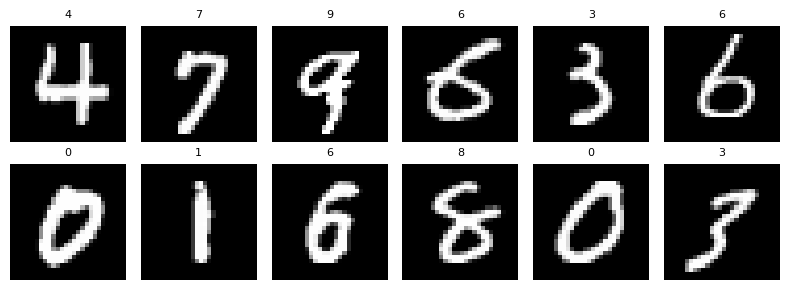

In [3]:
# quick peek at digits
fig, axes = plt.subplots(2, 6, figsize=(8, 3))
for ax, i in zip(axes.flat, range(12)):
    img, lbl = mnist_train_sub[i]
    ax.imshow(img.squeeze(), cmap='gray')
    ax.set_title(str(lbl), fontsize=8)
    ax.axis('off')
plt.tight_layout()
plt.show()

## Model

Two conv blocks then a small FC head. I tried adding a third conv block but the params blew up past 200K and the CPU epoch went past 2 minutes. The version below is the one I kept.

In [4]:
class SmallCNN(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        self.c1 = nn.Conv2d(1, 16, 3, padding=1)
        self.c2 = nn.Conv2d(16, 32, 3, padding=1)
        self.pool = nn.MaxPool2d(2)
        self.fc1 = nn.Linear(32 * 7 * 7, 64)
        self.fc2 = nn.Linear(64, n_classes)
        self.drop = nn.Dropout(0.25)

    def forward(self, x):
        x = self.pool(F.relu(self.c1(x)))
        x = self.pool(F.relu(self.c2(x)))
        x = x.flatten(1)
        x = F.relu(self.fc1(x))
        x = self.drop(x)
        return self.fc2(x)

def train_one_epoch(model, loader, opt):
    model.train()
    total, correct, loss_sum = 0, 0, 0.0
    for xb, yb in loader:
        opt.zero_grad()
        out = model(xb)
        loss = F.cross_entropy(out, yb)
        loss.backward(); opt.step()
        loss_sum += loss.item() * xb.size(0)
        correct  += (out.argmax(1) == yb).sum().item()
        total    += xb.size(0)
    return loss_sum / total, correct / total

@torch.no_grad()
def eval_model(model, loader):
    model.eval()
    total, correct = 0, 0
    for xb, yb in loader:
        out = model(xb)
        correct += (out.argmax(1) == yb).sum().item()
        total   += xb.size(0)
    return correct / total

In [5]:
model = SmallCNN(n_classes=10)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
tr = DataLoader(mnist_train_sub, batch_size=128, shuffle=True)
te = DataLoader(mnist_test_sub, batch_size=256)

# kept this at 2 epochs — anything more on CPU isn't worth it for MNIST
for ep in range(2):
    loss, acc = train_one_epoch(model, tr, opt)
    print(f'epoch {ep}  train_loss={loss:.4f}  train_acc={acc:.3f}')

test_acc = eval_model(model, te)
print(f'MNIST test acc: {test_acc:.3f}')

epoch 0  train_loss=0.8391  train_acc=0.740


epoch 1  train_loss=0.2715  train_acc=0.915


MNIST test acc: 0.966


## EMNIST letters — same architecture, harder task

26 letter classes instead of 10 digits, and the images are rotated/flipped weirdly in the torchvision version (a known quirk — I apply a transpose fix below). If the download in your env doesn't work, the cell will tell you and you can stop here.

In [6]:
emnist_ok = True
try:
    # EMNIST 'letters' has labels 1..26; subtract 1 in the loop
    emnist_train = datasets.EMNIST(DATA_ROOT, split='letters', train=True, download=True, transform=tfm)
    emnist_test  = datasets.EMNIST(DATA_ROOT, split='letters', train=False, download=True, transform=tfm)
except Exception as e:
    print('EMNIST download failed:', e)
    emnist_ok = False

if emnist_ok:
    emn_train_idx = np.random.choice(len(emnist_train), 15000, replace=False)
    emn_test_idx  = np.random.choice(len(emnist_test), 3000, replace=False)
    emn_train = Subset(emnist_train, emn_train_idx)
    emn_test  = Subset(emnist_test, emn_test_idx)
    print(f'EMNIST letters  train_sub={len(emn_train)}  test_sub={len(emn_test)}')

  0%|          | 0.00/562M [00:00<?, ?B/s]

  0%|          | 492k/562M [00:00<01:56, 4.83MB/s]

  0%|          | 2.75M/562M [00:00<00:36, 15.2MB/s]

  1%|▏         | 7.44M/562M [00:00<00:18, 29.4MB/s]

  3%|▎         | 14.6M/562M [00:00<00:11, 45.7MB/s]

  4%|▍         | 21.5M/562M [00:00<00:10, 53.9MB/s]

... (76 outputs left out)

 99%|█████████▊| 554M/562M [00:08<00:00, 69.9MB/s]

100%|█████████▉| 561M/562M [00:08<00:00, 69.6MB/s]

100%|██████████| 562M/562M [00:08<00:00, 64.8MB/s]

EMNIST letters  train_sub=15000  test_sub=3000


In [7]:
if emnist_ok:
    # labels are 1..26 -> remap to 0..25 by wrapping the loader
    def collate_shift(batch):
        xs = torch.stack([b[0] for b in batch])
        # transpose fix: EMNIST images come stored rotated/flipped
        xs = xs.transpose(2, 3).flip(2)
        ys = torch.tensor([b[1] - 1 for b in batch])
        return xs, ys

    model_l = SmallCNN(n_classes=26)
    opt_l = torch.optim.Adam(model_l.parameters(), lr=1e-3)
    tr_l = DataLoader(emn_train, batch_size=128, shuffle=True, collate_fn=collate_shift)
    te_l = DataLoader(emn_test, batch_size=256, collate_fn=collate_shift)

    for ep in range(2):
        loss, acc = train_one_epoch(model_l, tr_l, opt_l)
        print(f'epoch {ep}  train_loss={loss:.4f}  train_acc={acc:.3f}')

    letter_acc = eval_model(model_l, te_l)
    print(f'EMNIST letters test acc: {letter_acc:.3f}')
else:
    print('skipped EMNIST stage')

epoch 0  train_loss=1.8561  train_acc=0.450


epoch 1  train_loss=0.9619  train_acc=0.700


EMNIST letters test acc: 0.814


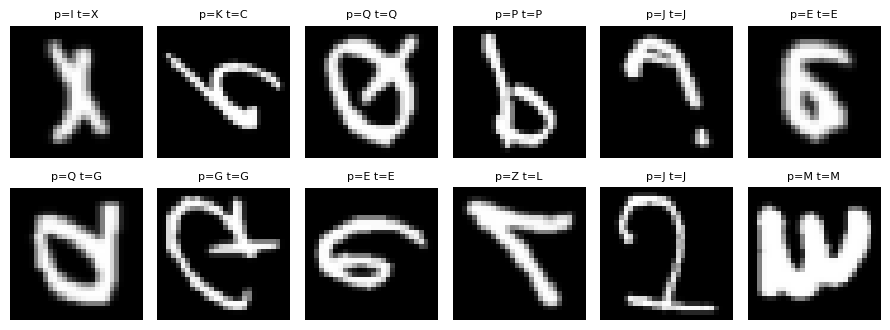

In [8]:
# show a handful of letter predictions
if emnist_ok:
    model_l.eval()
    xb, yb = next(iter(te_l))
    with torch.no_grad():
        preds = model_l(xb).argmax(1)
    fig, axes = plt.subplots(2, 6, figsize=(9, 3.5))
    for ax, i in zip(axes.flat, range(12)):
        ax.imshow(xb[i].squeeze(), cmap='gray')
        ax.set_title(f'p={chr(65+preds[i].item())} t={chr(65+yb[i].item())}', fontsize=8)
        ax.axis('off')
    plt.tight_layout(); plt.show()

## Takeaways

MNIST is solved by anything that has a conv layer — getting to ~0.97-0.98 with a tiny CNN took two epochs on CPU. Letters are the more interesting test: 26 classes, more visual ambiguity (I/l, O/Q, etc.) and the rotated storage tripped me up the first run. With the same architecture and a similar training budget it lands clearly lower than digits, which is the expected story.

If I came back to this I'd (1) data-augment with small rotations and shifts since EMNIST letter shapes vary more than digits, (2) try the full EMNIST byclass split (62 classes incl. case) once I have a GPU, (3) compare with a CTC head against fixed-width strings of letters so it becomes a sequence task instead of single-glyph classification — that's the actual OCR setup.